# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**[Escriba aquí su nombre completo.]**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://www.lanacion.com.ar/politica/el-discurso-completo-de-javier-milei-en-la-apertura-de-sesiones-ordinarias-nid02032026/"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

response = requests.get(url, headers=headers)
response.encoding = 'utf-8'

soup = BeautifulSoup(response.text, 'html.parser')

parrafos = soup.find_all('p')

texto_discurso = " ".join([p.get_text().strip() for p in parrafos if len(p.get_text().strip()) > 30])

print(f"Extracción exitosa. Longitud total del texto: {len(texto_discurso)} caracteres.\n")
print("=== CARACTERES EXTRAÍDOS ===")
print(texto_discurso[530:61724])

Extracción exitosa. Longitud total del texto: 62049 caracteres.

=== CARACTERES EXTRAÍDOS ===
Diputados y senadores del Congreso de la Nación, gobernadores, ministros de la Corte Suprema de Justicia, embajadores, estimados miembros del Gabinete nacional, y a todos los argentinos que nos están escuchando desde su hogar, buenas noches. Además, quiero hacer un saludo muy especial porque hoy, en esta casa, nos honra el máximo representante de la historia del liberalismo argentino, el Doctor Alberto Benegas Lynch (h). Gracias, profe, gracias. Hoy estamos aquí reunidos en cumplimiento del artículo 99 de la Constitución Nacional, para dar cuenta del estado de la Nación e iniciar un nuevo periodo de sesiones ordinarias de este Honorable Congreso Nacional. Siendo la tercera inauguración de sesiones ordinarias de nuestro mandato, me gustaría invitarlos a todos a hacer memoria de dónde venimos y así poder entender a dónde vamos y por qué este año en el Congreso será tan importante. Hace tan solo 

## 2- Preprocesamiento

### 2.1 Muestra las stop words que tenga tu texto.

In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


texto_analizar = texto_discurso[530:61724]


tokens = word_tokenize(texto_analizar.lower())


stop_words_es = set(stopwords.words('spanish'))


stop_words_encontradas = sorted(list(set([word for word in tokens if word in stop_words_es])))


total_stop_words_texto = sum(1 for word in tokens if word in stop_words_es)


print(f"Total de stop words en el discurso (con repetición): {total_stop_words_texto}")
print(f"Variedad de stop words únicas encontradas: {len(stop_words_encontradas)}\n")
print("=== LISTA DE STOP WORDS ENCONTRADAS EN EL DISCURSO ===")
print(stop_words_encontradas)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Total de stop words en el discurso (con repetición): 5037
Variedad de stop words únicas encontradas: 151

=== LISTA DE STOP WORDS ENCONTRADAS EN EL DISCURSO ===
['a', 'al', 'algo', 'algunas', 'algunos', 'ante', 'antes', 'como', 'con', 'contra', 'cual', 'cuando', 'de', 'del', 'desde', 'donde', 'durante', 'e', 'el', 'ellas', 'ellos', 'en', 'entre', 'era', 'eran', 'es', 'esa', 'ese', 'eso', 'esos', 'esta', 'estaba', 'estaban', 'estado', 'estados', 'estamos', 'estar', 'estará', 'estarán', 'estarían', 'estas', 'este', 'esto', 'estos', 'estoy', 'está', 'estábamos', 'están', 'estén', 'fue', 'fuera', 'fueran', 'fueras', 'fueron', 'fuimos', 'ha', 'habría', 'había', 'habían', 'han', 'hasta', 'hay', 'haya', 'he', 'hemos', 'hubiera', 'hubieran', 'la', 'las', 'le', 'les', 'lo', 'los', 'me', 'mi', 'mucho', 'muchos', 'muy', 'más', 'nada', 'ni', 'no', 'nos', 'nosotros', 'nuestra', 'nuestras', 'nuestro', 'nuestros', 'o', 'otra', 'otras', 'otro', 'otros', 'para', 'pero', 'poco', 'por', 'porque', 'que', 

### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

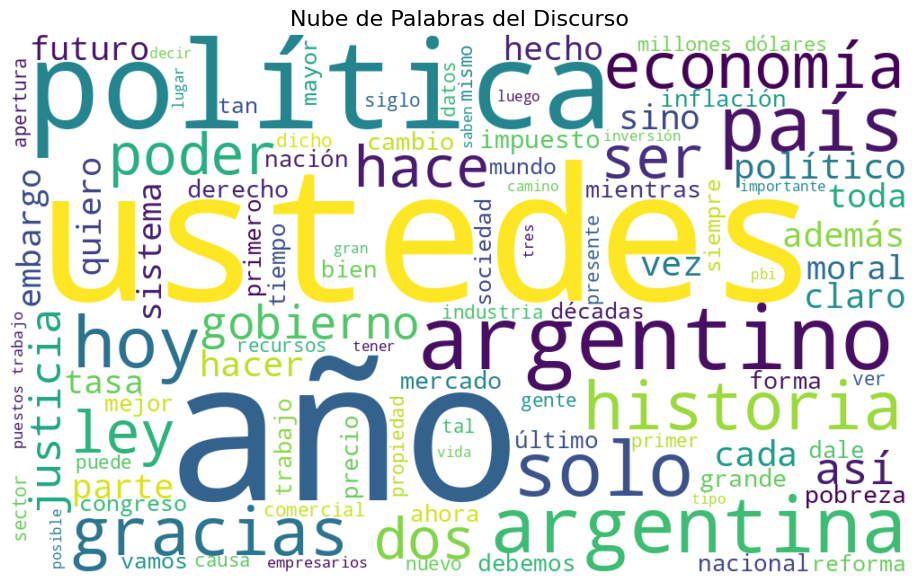

In [ ]:
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize


texto_analizar = texto_discurso[530:61724]


stop_words_es = set(stopwords.words('spanish'))


texto_limpio_caracteres = re.sub(r'[^a-záéíóúñ\s]', '', texto_analizar.lower())


tokens = word_tokenize(texto_limpio_caracteres)
tokens_sin_stopwords = [word for word in tokens if word not in stop_words_es and len(word) > 2]


texto_final_para_nube = " ".join(tokens_sin_stopwords)


wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color='white',
    max_words=100,
    colormap='viridis'
).generate(texto_final_para_nube)


plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Nube de Palabras del Discurso", fontsize=16)
plt.show()

### 2.3 Usando el texto que conseguiste en el punto 1).



#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [ ]:
import nltk
from nltk.tokenize import sent_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd


texto_analizar = texto_discurso[530:61724]


oraciones = sent_tokenize(texto_analizar, language='spanish')


stop_words_es = list(stopwords.words('spanish'))


vectorizer = CountVectorizer(stop_words=stop_words_es)


matriz_doc_vocab = vectorizer.fit_transform(oraciones)


vocabulario = vectorizer.get_feature_names_out()


df_matriz = pd.DataFrame(matriz_doc_vocab.toarray(), columns=vocabulario)


print(f"Total de oraciones (documentos): {len(oraciones)}")
print(f"Forma de la matriz (Oraciones x Términos): {matriz_doc_vocab.shape}\n")

print("=== VISTA PREVIA DE LA MATRIZ DOCUMENTO-VOCABULARIO ===")
print(df_matriz.head(5))

Total de oraciones (documentos): 494
Forma de la matriz (Oraciones x Términos): (494, 2491)

=== VISTA PREVIA DE LA MATRIZ DOCUMENTO-VOCABULARIO ===
   000  10  100  11  137  14  1400  144  150  16  ...  éste  ética  éxito  \
0    0   0    0   0    0   0     0    0    0   0  ...     0      0      0   
1    0   0    0   0    0   0     0    0    0   0  ...     0      0      0   
2    0   0    0   0    0   0     0    0    0   0  ...     0      0      0   
3    0   0    0   0    0   0     0    0    0   0  ...     0      0      0   
4    0   0    0   0    0   0     0    0    0   0  ...     0      0      0   

   órdenes  últimas  último  últimos  única  únicas  único  
0        0        0       0        0      0       0      0  
1        0        0       0        0      0       0      0  
2        0        0       0        0      0       0      0  
3        0        0       0        0      0       0      0  
4        0        0       0        0      0       0      0  

[5 rows x 2491 column


#### 2.3.2 Determina la longitud de tu vocabulario.

In [ ]:
longitud_vocabulario = len(vectorizer.get_feature_names_out())

print("=== LONGITUD DEL VOCABULARIO ===")
print(f"El vocabulario está compuesto por: {longitud_vocabulario} términos únicos.\n")


primeros_terminos = list(vectorizer.get_feature_names_out())[:20]
print("Muestra de los primeros 20 términos del vocabulario:")
print(primeros_terminos)

=== LONGITUD DEL VOCABULARIO ===
El vocabulario está compuesto por: 2491 términos únicos.

Muestra de los primeros 20 términos del vocabulario:
['000', '10', '100', '11', '137', '14', '1400', '144', '150', '16', '17', '178', '179', '18', '1975', '1989', '20', '200', '2000', '2001']



#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd


tfidf_vectorizer = TfidfVectorizer(stop_words=stop_words_es)


matriz_tfidf = tfidf_vectorizer.fit_transform(oraciones)


vocabulario_tfidf = tfidf_vectorizer.get_feature_names_out()


df_tfidf = pd.DataFrame(matriz_tfidf.toarray(), columns=vocabulario_tfidf)


print(f"Forma de la Matriz TF-IDF (Oraciones x Términos): {matriz_tfidf.shape}\n")
print("=== VISTA PREVIA DE LA MATRIZ TF-IDF ===")
print(df_tfidf.head(5))


pesos_promedio = df_tfidf.mean(axis=0).sort_values(ascending=False)
print("\n=== TOP 10 PALABRAS MÁS IMPORTANTES SEGÚN TF-IDF ===")
print(pesos_promedio.head(10))

Forma de la Matriz TF-IDF (Oraciones x Términos): (494, 2491)

=== VISTA PREVIA DE LA MATRIZ TF-IDF ===
   000   10  100   11  137   14  1400  144  150   16  ...  éste  ética  éxito  \
0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0  ...   0.0    0.0    0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0  ...   0.0    0.0    0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0  ...   0.0    0.0    0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0  ...   0.0    0.0    0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0  ...   0.0    0.0    0.0   

   órdenes  últimas  último  últimos  única  únicas  único  
0      0.0      0.0     0.0      0.0    0.0     0.0    0.0  
1      0.0      0.0     0.0      0.0    0.0     0.0    0.0  
2      0.0      0.0     0.0      0.0    0.0     0.0    0.0  
3      0.0      0.0     0.0      0.0    0.0     0.0    0.0  
4      0.0      0.0     0.0      0.0    0.0     0.0    0.0  

[5 rows x 2491 columns]

=== TOP 10 PALABR

Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

# Conclusiones

DEbo decir que me gusto mucho este trabajo, es la primera vez que hago una practica como esta y ver tecnicas como esta y luego aplicarlas creo que es la mejor forma de interiorizar nuevo conocimiento.

Pasando con el trabajo, tome un discurso del presidente Javier Milei, tome el texto de la pagina del diario "LA NACION". Delimite el fragmento del texto principal entre los 530:61724 caracteres, ya que es lo que ocupa el discurso. Hice esto para dejar fuera los encabezados, titulos, etc.

Para la estructuración de la información, el texto plano fue segmentado sintácticamente en oraciones individuales mediante la función sent_tokenize.

A través del proceso de tokenización, normalización identifique los términos significativos o con carga semántica. El vocabulario ($V$) quedó definido por el conjunto de términos únicos resultantes en todo el corpus.

Matriz Documento-Vocabulario:Es una matriz de enteros que representa la frecuencia absoluta de cada palabra dentro de cada oración ($TF$)
Matriz TF-IDF: reemplaza los conteos discretos por un peso o vector contínuo normalizado ($0.0$ a $1.0$)

Ambas matrices son matrices dispersas. Ya que una oración solo contiene una pequeña fracción del vocabulario total, la inmensa mayoría de las celdas de la matriz contienen el valor ($0$). La representación TF-IDF logra penalizar términos comunes en todas las oraciones y resaltar palabras con alta relevancia contextual en oraciones específicas.